# Calculates the variability feedback with a regression. 


Note, was variability_regression_mostrecent_ensoremoved_coarsenandstddeviation_sst.ipynb in previous folders

# Remove ENSO linear regression

In [1]:
import xarray as xr
cwd = %pwd
path = cwd + "/data/temp_detrend_linear_regression_enso_norollingmean_sst_oct2026.nc"

temp = xr.open_dataset(path)
temp = temp.__xarray_dataarray_variable__


path = cwd + "/data/toa_detrend_linear_regression_enso_norollingmean_sst_oct2026.nc"

flux = xr.open_dataset(path)
flux = flux.__xarray_dataarray_variable__

#already meaned in lon

In [2]:
import xarray as xr
import numpy as np
from scipy import stats


# choose time
period1 = slice("2000-01-01", "2025-01-01")
temp = temp.sel(time=period1)
flux = flux.sel(time=period1)

# get ensemble_anomalies
temp_anom = temp - temp.mean(dim="ensemble_member")
flux_anom = flux - flux.mean(dim="ensemble_member")

temp_anom=temp_anom.resample(time="Y").mean()
flux_anom=flux_anom.resample(time="Y").mean()

n_ens = temp.sizes["ensemble_member"]
grid_points = temp.sizes["lat"]

# get values
temp_flat=temp_anom.values
flux_flat=flux_anom.values

# initialize storage
slopes = np.empty(grid_points)
intercepts = np.empty(grid_points)
r = np.empty(grid_points)
slope_stderr = np.empty(grid_points)

# regress per grid point
for g in range(grid_points):
    # stack time × ensemble for each grid point
    x = temp_flat[:, :, g].reshape(-1)
    y = flux_flat[:, :, g].reshape(-1)
   
    # slope, intercept, r_value, p_value, std_err
    res = stats.linregress(x, y)

    slopes[g] = res.slope
    slope_stderr[g] = res.stderr
    r[g] = res.rvalue

    
    intercepts[g] = res.intercept


# add back to xarray
slopes_xr = xr.DataArray(slopes, dims=("lat"), coords={"lat": temp.lat}, name="regression_slope")
slopes_stderr_xr = xr.DataArray(slope_stderr, dims=("lat"), coords={"lat": temp.lat}, name="regression_slope_stderr")

intercepts_xr = xr.DataArray(intercepts, dims=("lat"), coords={"lat": temp.lat}, name="regression_intercept")
r_xr = xr.DataArray(r, dims=("lat"), coords={"lat": temp.lat}, name="regression_r2")

<string>:7: FutureWarning: 'Y' is deprecated and will be removed in a future version. Please use 'YE' instead of 'Y'.
<string>:7: FutureWarning: 'Y' is deprecated and will be removed in a future version. Please use 'YE' instead of 'Y'.


In [3]:
residual_std_period1=(flux_anom-slopes_xr*temp_anom).stack(z=('ensemble_member', 'time')).std('z')
residual_mean_period1=(flux_anom-slopes_xr*temp_anom).stack(z=('ensemble_member', 'time')).mean('z')

In [4]:
temp = xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/temp_detrend_linear_regression_enso_norollingmean_sst.nc')
temp = temp.__xarray_dataarray_variable__

flux = xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/toa_detrend_linear_regression_enso_sst.nc')
flux = flux.__xarray_dataarray_variable__

#already meaned in lon


# choose time
period2 = slice("2075-01-01", "2100-01-01")
temp = temp.sel(time=period2)
flux = flux.sel(time=period2)

# get ensemble_anomalies
temp_anom = temp - temp.mean(dim="ensemble_member")
flux_anom = flux - flux.mean(dim="ensemble_member")

temp_anom=temp_anom.resample(time="Y").mean()
flux_anom=flux_anom.resample(time="Y").mean()

n_ens = temp.sizes["ensemble_member"]
grid_points = temp.sizes["lat"]

# get values
temp_flat=temp_anom.values
flux_flat=flux_anom.values

# initialize storage
slopes = np.empty(grid_points)
intercepts = np.empty(grid_points)
r = np.empty(grid_points)
slope_stderr = np.empty(grid_points)

# regress per grid point
for g in range(grid_points):
    # stack time × ensemble for each grid point
    x = temp_flat[:, :, g].reshape(-1)
    y = flux_flat[:, :, g].reshape(-1)
   
    # slope, intercept, r_value, p_value, std_err
    res = stats.linregress(x, y)

    slopes[g] = res.slope
    slope_stderr[g] = res.stderr
    r[g] = res.rvalue

    
    intercepts[g] = res.intercept


# add back to xarray
slopes_xr2 = xr.DataArray(slopes, dims=("lat"), coords={"lat": temp.lat}, name="regression_slope")
slopes_stderr_xr2 = xr.DataArray(slope_stderr, dims=("lat"), coords={"lat": temp.lat}, name="regression_slope_stderr")

intercepts_xr2 = xr.DataArray(intercepts, dims=("lat"), coords={"lat": temp.lat}, name="regression_intercept")
r_xr2 = xr.DataArray(r, dims=("lat"), coords={"lat": temp.lat}, name="regression_r2")

<string>:7: FutureWarning: 'Y' is deprecated and will be removed in a future version. Please use 'YE' instead of 'Y'.
<string>:7: FutureWarning: 'Y' is deprecated and will be removed in a future version. Please use 'YE' instead of 'Y'.


In [5]:
residual_std_period2=(flux_anom-slopes_xr2*temp_anom).stack(z=('ensemble_member', 'time')).std('z')
residual_mean_period2=(flux_anom-slopes_xr2*temp_anom).stack(z=('ensemble_member', 'time')).mean('z')

Text(0.5, 0.98, 'Estimate of feedback paramater with regression TOA\n Computed with anomalies from the ensemble mean for month and then regressing')

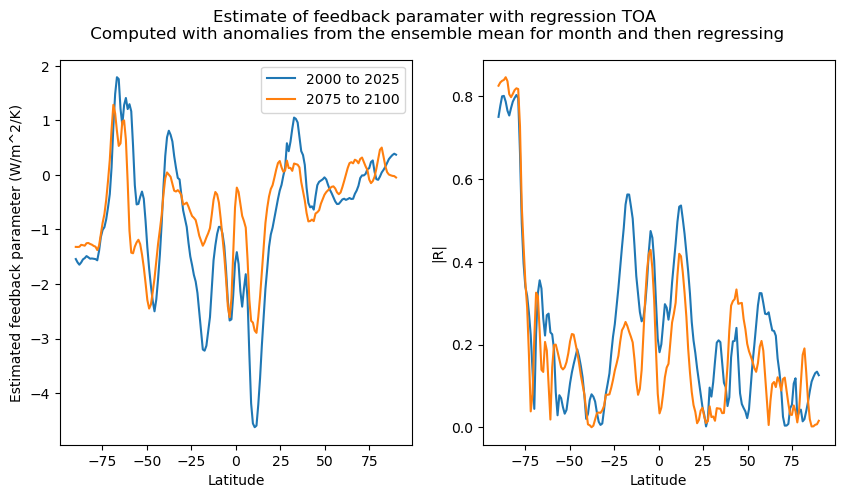

In [8]:
import matplotlib.pyplot as plt
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,5))

(slopes_xr).plot(ax=ax1)
(slopes_xr2).plot(ax=ax1)

ax1.set_xlabel('Latitude')
ax1.set_ylabel('Estimated feedback parameter (W/m^2/K)')
ax1.legend(['2000 to 2025','2075 to 2100'])


(np.abs(r_xr)).plot(ax=ax2)
(np.abs(r_xr2)).plot(ax=ax2)
ax2.set_xlabel('Latitude')
ax2.set_ylabel('|R|')

fig.suptitle('Estimate of feedback paramater with regression TOA\n Computed with anomalies from the ensemble mean for month and then regressing')



In [9]:
ds_period1 = xr.Dataset(data_vars={'slope': slopes_xr,'stderr': slopes_stderr_xr})
ds_period2 = xr.Dataset(data_vars={'slope': slopes_xr2,'stderr': slopes_stderr_xr2})

ds_period1.to_netcdf(cwd+"/data/variability_feedback_2000to2025_sst_oct2026.nc") #we checked this is exactly the same as "/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/variability_feedback_2000to2025_sst.nc"
ds_period2.to_netcdf(cwd+"/data/variability_feedback_2075to2100_sst_oct2026.nc")

In [10]:
ds_period1 = xr.Dataset(data_vars={'sigma': residual_std_period1})
ds_period2 = xr.Dataset(data_vars={'sigma': residual_std_period2})

ds_period1.to_netcdf(cwd+"/data/variability_sigma_2000to2025_sst_oct2026.nc") #we checked this is exactly the same as "/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/variability_sigma_2000to2025_sst.nc"
ds_period2.to_netcdf(cwd+"/data/variability_sigma_2075to2100_sst_oct2026.nc")